# 01 Official split: train, validation and test

Final units are trained on the official training recordings at a fixed epoch chosen by source cross-validation; they have no
validation set of their own. Validation curves therefore come from the 5-fold x 5-seed source CV (`fivefold-20261026`).
Test = official test recordings (2,756 cycles), last epoch, seeds 0-4. Figures: `outputs/figures/official/`.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/common.py
sys.path.insert(0, str(Path.cwd().parent))   # repository root for src.*
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from common import *
pd.set_option('display.precision', 2); pd.set_option('display.width', 160)
FIG, TAB = out_dirs('official')
ARM_LIST = [a for a in ARMS if all(exists(a, 'official', s) for s in range(5))]
print(ARM_LIST)

['anchor', 'swa', 'multiscale', 'pcsl5_control', 'class_aware_light', 'lora', 'lora_class_aware', 'kd_g4_k1', 'kd_g4_k2', 'kd_g7_k2']


## 1. Test metrics per arm (official test, last epoch)

In [2]:
rows = []
for a in ARM_LIST:
    for s in range(5):
        t = report(a, 'official', s)['last']['test']['all']
        rows.append(dict(arm=a, seed=s, score=t['score'], sp=t['sp'], se=t['se'], hs=t['hs'], macro_f1=100 * t['macro_f1'],
                         score_2cls=t['two_cls_score'], **{f'recall_{c}': r for c, r in zip(CLASSES, t['recall'])}))
for s in range(5):
    p, y, d, _ = ensemble(G4, 'official', s)
    sp, se, sc = icbhi_score(p, y)
    rows.append(dict(arm='G4 ensemble', seed=s, score=sc, sp=sp, se=se, hs=2 * sp * se / (sp + se),
                     **{f'recall_{c}': 100 * (p.argmax(1)[y == i] == i).mean() for i, c in enumerate(CLASSES)}))
off = pd.DataFrame(rows)
summary = off.groupby('arm').agg(['mean', 'std']).drop(columns='seed').sort_values(('score', 'mean'), ascending=False)
summary.to_csv(TAB / 'official_test_summary.csv'); off.to_csv(TAB / 'official_test_per_seed.csv', index=False)
summary[[(m, 'mean') for m in ['score', 'sp', 'se', 'hs', 'macro_f1', 'score_2cls']] + [('score', 'std')]]

,score,sp,se,hs,macro_f1,score_2cls,score
,mean,mean,mean,mean,mean,mean,std
arm,,,,,,,
kd_g4_k1,64.15,74.53,53.78,62.46,54.05,71.48,0.36
G4 ensemble,64.11,75.96,52.27,61.91,NaN,NaN,0.65
kd_g4_k2,63.47,73.12,53.81,61.95,53.80,70.76,0.67
swa,63.32,75.85,50.79,60.82,52.68,70.55,0.43
anchor,63.13,75.33,50.94,60.73,51.90,70.36,1.19
kd_g7_k2,62.75,72.60,52.90,61.15,52.76,70.35,0.42
multiscale,62.45,75.05,49.86,59.88,52.08,69.99,0.81
pcsl5_control,62.16,73.27,51.05,60.09,51.72,69.39,0.89


PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/official/test_score_by_arm.png')

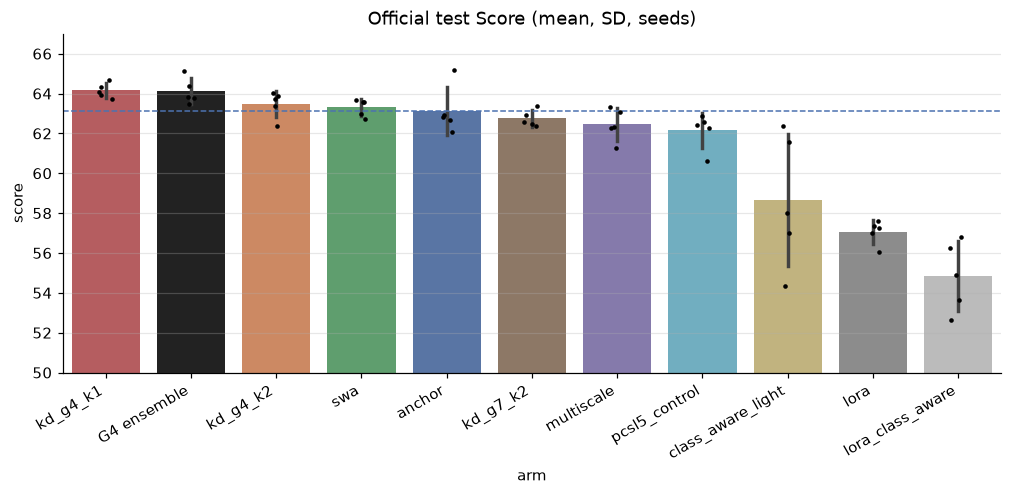

In [3]:
order = summary.index.tolist()
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=off, x='arm', y='score', order=order, palette=[PALETTE.get(a, '#999') for a in order], errorbar='sd', ax=ax)
sns.stripplot(data=off, x='arm', y='score', order=order, color='k', size=3, ax=ax)
ax.axhline(off[off.arm == 'anchor'].score.mean(), color=PALETTE['anchor'], ls='--', lw=1)
ax.set_ylim(50, 67); ax.set_title('Official test Score (mean, SD, seeds)'); plt.xticks(rotation=30, ha='right')
savefig(fig, FIG, 'test_score_by_arm')

## 2. Paired difference to the anchor (same seed)

,mean,std,seeds_above
arm,,,
G4 ensemble,0.98,0.68,4
class_aware_light,-4.47,3.80,0
kd_g4_k1,1.02,0.93,4
kd_g4_k2,0.33,1.19,3
kd_g7_k2,-0.38,0.89,2
lora,-6.09,1.24,0
lora_class_aware,-8.28,1.38,0
multiscale,-0.68,1.10,2
pcsl5_control,-0.97,1.33,1


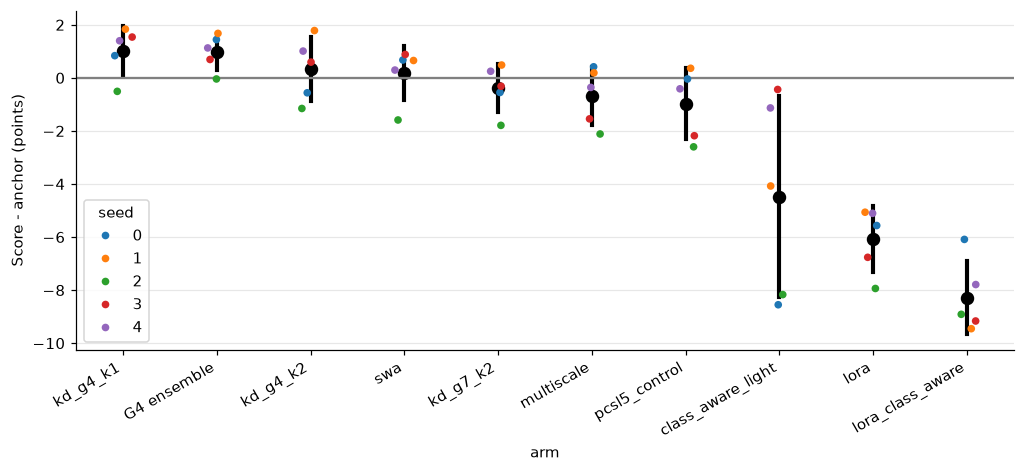

In [4]:
base = off[off.arm == 'anchor'].set_index('seed').score
d = off[off.arm != 'anchor'].assign(delta=lambda x: x.score - x.seed.map(base))
fig, ax = plt.subplots(figsize=(11, 4))
sns.pointplot(data=d, x='arm', y='delta', order=[o for o in order if o != 'anchor'], errorbar='sd', join=False, ax=ax, color='k')
sns.stripplot(data=d, x='arm', y='delta', order=[o for o in order if o != 'anchor'], hue='seed', palette='tab10', size=5, ax=ax)
ax.axhline(0, color='grey'); ax.set_ylabel('Score - anchor (points)'); plt.xticks(rotation=30, ha='right')
savefig(fig, FIG, 'paired_delta_vs_anchor')
d.groupby('arm').delta.agg(['mean', 'std', lambda s: (s > 0).sum()]).rename(columns={'<lambda_0>': 'seeds_above'})

## 3. Training curves (train loss and accuracy, test Score per epoch)

The test Score per epoch is shown for reading only; the epoch was fixed beforehand from the source CV.

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/official/training_curves.png')

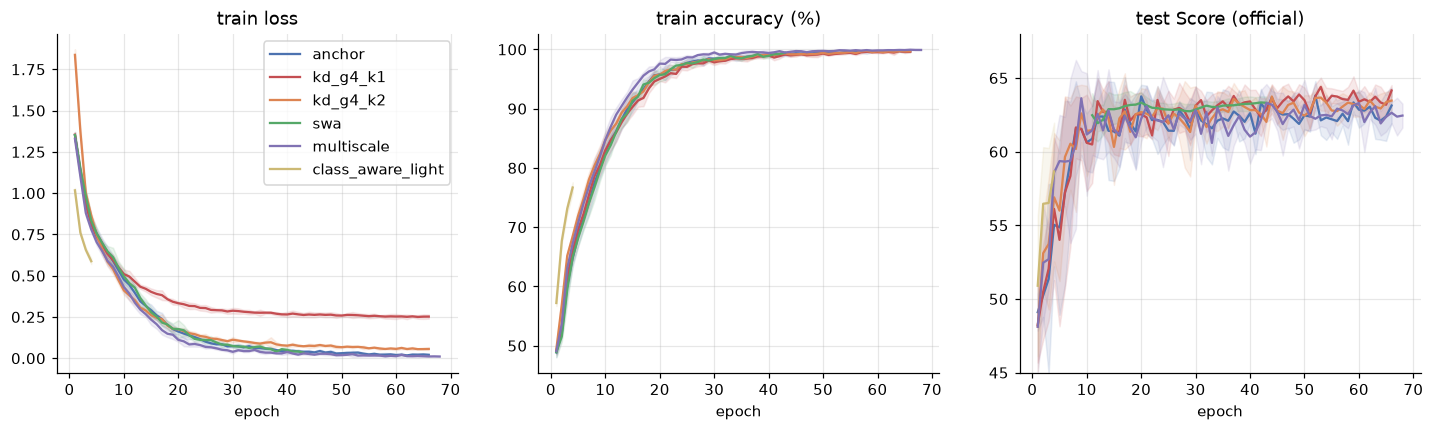

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a in ['anchor', 'kd_g4_k1', 'kd_g4_k2', 'swa', 'multiscale', 'class_aware_light']:
    if a not in ARM_LIST: continue
    h = pd.concat([history(a, 'official', s).assign(seed=s) for s in range(5)])
    g = h.groupby('epoch')
    for i, col in enumerate(['train_loss', 'train_acc', 'test_score']):
        m, sd = g[col].mean(), g[col].std()
        ax[i].plot(m.index, m, label=a, color=PALETTE.get(a)); ax[i].fill_between(m.index, m - sd, m + sd, alpha=0.12, color=PALETTE.get(a))
for i, t in enumerate(['train loss', 'train accuracy (%)', 'test Score (official)']): ax[i].set_title(t); ax[i].set_xlabel('epoch')
ax[2].set_ylim(45, 68); ax[0].legend()
savefig(fig, FIG, 'training_curves')

## 4. Validation curves from source cross-validation (5 folds x 5 seeds)

arm
anchor               25
class_aware_light    25
lora                 25
lora_class_aware     25
multiscale           25
swa                  25
Name: units, dtype: int64


,max,idxmax
arm,,
anchor,60.59,"(anchor, 66)"
class_aware_light,62.05,"(class_aware_light, 4)"
lora,61.19,"(lora, 83)"
lora_class_aware,61.28,"(lora_class_aware, 43)"
multiscale,60.27,"(multiscale, 68)"
swa,60.66,"(swa, 43)"


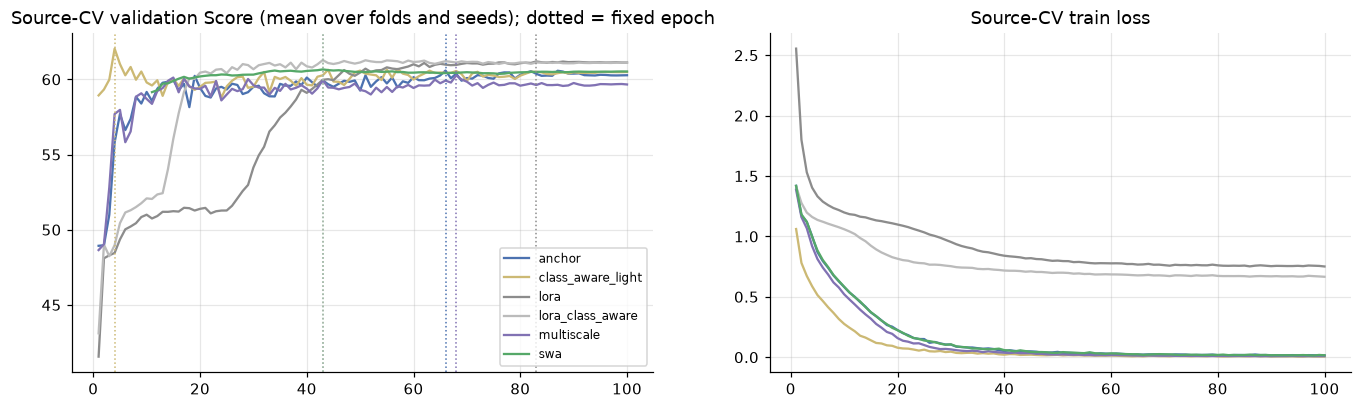

In [6]:
cv = []
for p in (REPO / 'outputs' / 'train').glob('fivefold-20261026-s*/*/cv*/report.json'):
    r = json.loads(p.read_text())
    for e in r['history']:
        cv.append(dict(arm=p.parent.parent.name, run=p.parent.parent.parent.name, fold=p.parent.name, epoch=e['epoch'],
                       val_score=e.get('val_score'), train_loss=e.get('train_loss'), train_acc=e.get('train_acc')))
cv = pd.DataFrame(cv)
print(cv.groupby('arm').apply(lambda g: g[['run', 'fold']].drop_duplicates().shape[0]).rename('units'))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, g in cv.groupby('arm'):
    m = g.groupby('epoch').val_score.mean(); ax[0].plot(m.index, m, label=a, color=PALETTE.get(a))
    m = g.groupby('epoch').train_loss.mean(); ax[1].plot(m.index, m, label=a, color=PALETTE.get(a))
for a, (_, _, ep) in ARMS.items():
    if a in cv.arm.unique(): ax[0].axvline(ep, color=PALETTE.get(a), ls=':', lw=1)
ax[0].set_title('Source-CV validation Score (mean over folds and seeds); dotted = fixed epoch'); ax[1].set_title('Source-CV train loss')
ax[0].legend(fontsize=8)
savefig(fig, FIG, 'validation_curves_cv')
cv.groupby(['arm', 'epoch']).val_score.mean().groupby('arm').agg(['max', 'idxmax'])

## 5. Confusion matrices (pooled over seeds)

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/official/confusion.png')

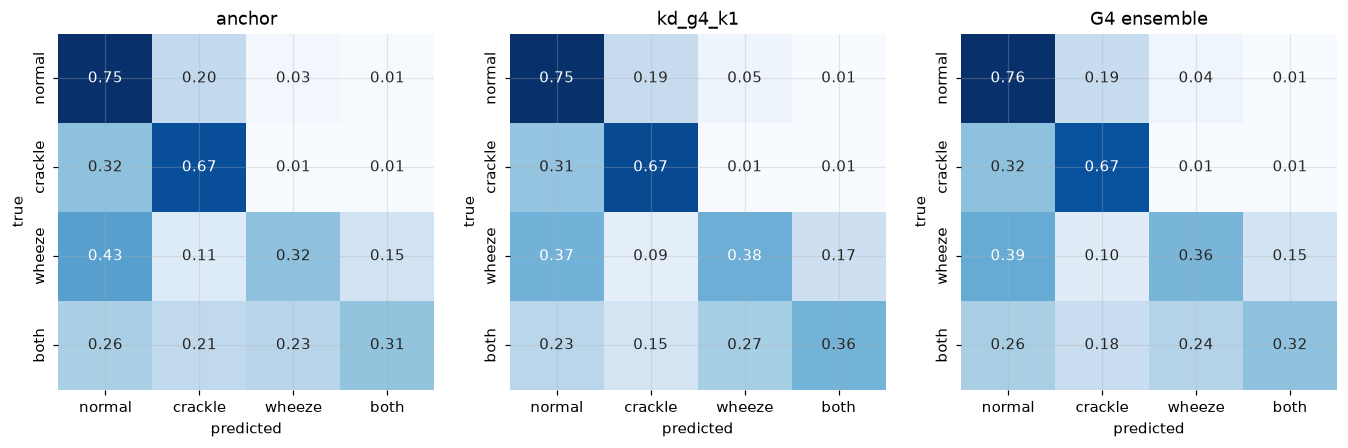

In [7]:
from sklearn.metrics import confusion_matrix
models = {'anchor': lambda s: preds('anchor', 'official', s), 'kd_g4_k1': lambda s: preds('kd_g4_k1', 'official', s),
          'G4 ensemble': lambda s: ensemble(G4, 'official', s)}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for i, (n, f) in enumerate(models.items()):
    cm = sum(confusion_matrix(f(s)[1], f(s)[0].argmax(1), labels=range(4)) for s in range(5))
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[i], cbar=False)
    ax[i].set_title(n); ax[i].set_xlabel('predicted'); ax[i].set_ylabel('true')
savefig(fig, FIG, 'confusion')

## 6. Per-class recall and per-device Score

arm,anchor,kd_g4_k1,multiscale,swa
device,,,,
AKGC417L,59.98,60.77,59.12,60.02
Litt3200,61.25,64.13,63.41,62.91
Meditron,65.30,67.12,64.42,65.66


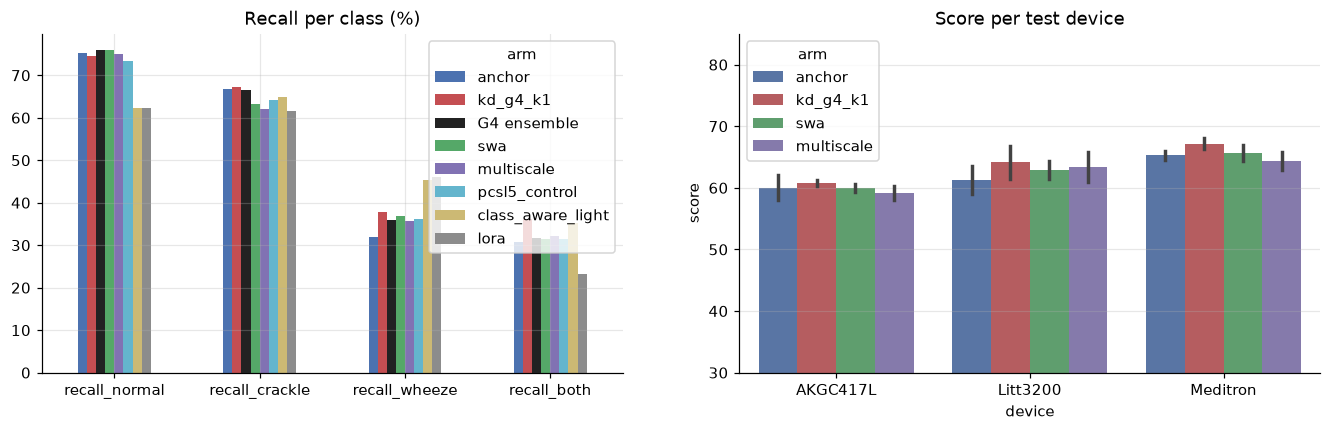

In [8]:
rec_cols = [f'recall_{c}' for c in CLASSES]
r = off.groupby('arm')[rec_cols].mean().loc[[a for a in ['anchor', 'kd_g4_k1', 'G4 ensemble', 'swa', 'multiscale', 'pcsl5_control', 'class_aware_light', 'lora'] if a in order]]
dev = []
for a in ['anchor', 'kd_g4_k1', 'swa', 'multiscale']:
    for s in range(5):
        for k, t in report(a, 'official', s)['last']['test'].items():
            if k != 'all': dev.append(dict(arm=a, device=k, seed=s, score=t['score'], n=t['n']))
dev = pd.DataFrame(dev)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
r.T.plot.bar(ax=ax[0], rot=0, color=[PALETTE.get(a) for a in r.index]); ax[0].set_title('Recall per class (%)')
sns.barplot(data=dev, x='device', y='score', hue='arm', palette=PALETTE, errorbar='sd', ax=ax[1]); ax[1].set_title('Score per test device'); ax[1].set_ylim(30, 85)
savefig(fig, FIG, 'recall_device')
dev.groupby(['device', 'arm']).score.mean().unstack().round(2)

## 7. Calibration (reliability of the top-class probability)

{'anchor': np.float64(0.31863372315516153),
 'kd_g4_k1': np.float64(0.19747725488139511),
 'G4 ensemble': np.float64(0.1798329346519942)}

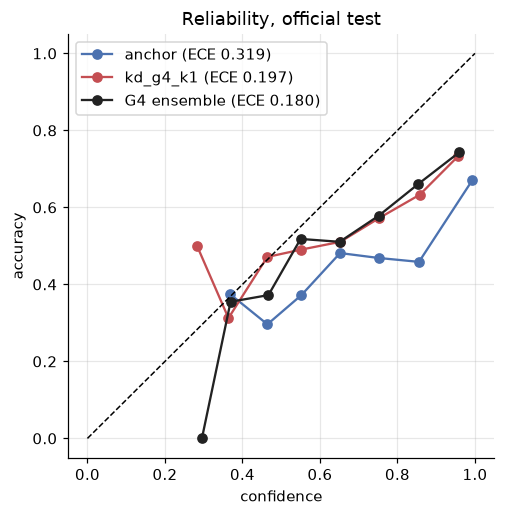

In [9]:
def reliability(p, y, bins=10):
    conf, ok = p.max(1), p.argmax(1) == y
    e = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(conf, e) - 1, 0, bins - 1)
    acc = np.array([ok[idx == b].mean() if (idx == b).any() else np.nan for b in range(bins)])
    cf = np.array([conf[idx == b].mean() if (idx == b).any() else np.nan for b in range(bins)])
    n = np.bincount(idx, minlength=bins)
    return cf, acc, np.nansum(n / n.sum() * np.abs(acc - cf))
fig, ax = plt.subplots(figsize=(5, 5)); ece = {}
for n, f in models.items():
    P = [f(s) for s in range(5)]
    cf, acc, e = reliability(np.concatenate([q[0] for q in P]), np.concatenate([q[1] for q in P]))
    ece[n] = e; ax.plot(cf, acc, 'o-', label=f'{n} (ECE {e:.3f})', color=PALETTE.get(n))
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlabel('confidence'); ax.set_ylabel('accuracy'); ax.legend(); ax.set_title('Reliability, official test')
savefig(fig, FIG, 'reliability'); ece

## Notes

- [Fact] Numbers are last-epoch official test results; all arms trained at fixed epochs chosen on source CV.
- [Fact] G4 ensemble and the distilled students are exploratory: the G4 group was chosen on the same test scores.
- [Interpretation] Training accuracy reaches ~99% for every arm; the test Score plateaus early, so differences between arms are
  differences in generalisation, not in fit.